# Reto 4 · Interpretación de los segmentos

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Objetivo: traducir los 6 clusters del Reto 3 a **perfiles de cliente** que un equipo de marketing pueda entender y
usar, cada uno con un **nombre**, sus **rasgos** y **acciones comerciales** concretas.

Para perfilar usamos dos tipos de variables:
- las **12 features del modelo**, en sus **unidades reales** (años, %, nº de vehículos), no escaladas;
- **variables de perfilado** que no entraron en el modelo: país, género, B2B, AMG, modelos, motorización,
  consentimientos por canal y telemetría.

Antes de poner nombres se comprueban las **trampas de interpretación** más probables (apartado 3).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from features import (cargar_datos, construir_pipeline, ajustar_kmeans, nombrar_segmentos, ORDEN_SEGMENTOS,
                      COLORES_SEGMENTOS, FEATURES, ORDEN_EDAD, SEMILLA, N_INIT_FINAL)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 200)

df = cargar_datos()
pipe = construir_pipeline()
X = pipe.fit_transform(df)
clientes = pipe.named_steps["agregar"].transform(df)
km = ajustar_kmeans(X)
clientes["cluster"] = km.labels_

## 1. Nombres de los segmentos

Los números de cluster (0-5) son arbitrarios: dependen de la semilla. Para que los nombres no dependan de ese número,
cada nombre se asigna con una **regla sobre los centroides** (el rasgo que define al segmento), definida en
`nombrar_segmentos` de `features.py`:
furgonetas → Gran Formato; electrificados → Pionero Eléctrico; menos canales → Contacto Solo Digital; más vehículos →
Premium Multivehículo; de los dos restantes, más visitas al taller → Fiel de Taller y menos → Recién Llegado de Ocasión.

In [2]:
cen = pd.DataFrame(km.cluster_centers_, columns=X.columns)
asignacion = nombrar_segmentos(cen)

ORDEN = ORDEN_SEGMENTOS
COLORES = COLORES_SEGMENTOS
clientes["segmento"] = pd.Categorical(clientes["cluster"].map(asignacion), categories=ORDEN, ordered=True)
pd.Series(asignacion, name="segmento").sort_index().to_frame()

,segmento
0,Contacto Solo Digital
1,Fiel de Taller
2,Recién Llegado de Ocasión
3,Pionero Eléctrico
4,Gran Formato
5,Premium Multivehículo


## 2. Perfil de cada segmento

### 2.1 Tamaño

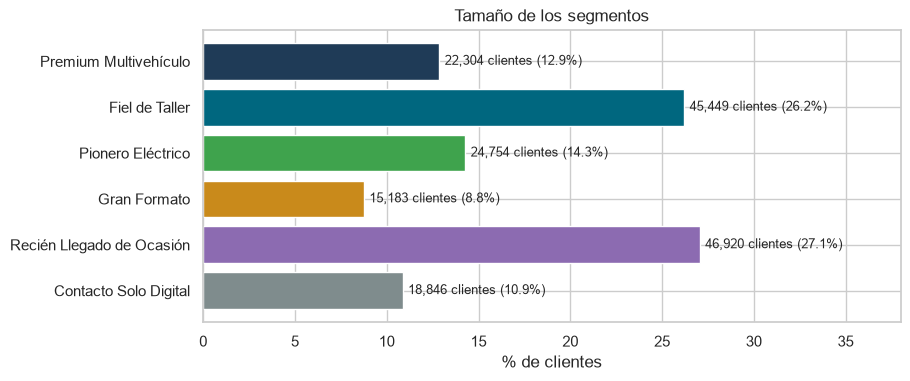

In [3]:
tam = clientes["segmento"].value_counts().reindex(ORDEN)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(ORDEN, tam / len(clientes) * 100, color=[COLORES[s] for s in ORDEN])
for i, n in enumerate(tam):
    ax.text(n / len(clientes) * 100 + .3, i, f"{n:,} clientes ({n / len(clientes):.1%})", va="center", fontsize=9)
ax.invert_yaxis()
ax.set(title="Tamaño de los segmentos", xlabel="% de clientes", xlim=(0, 38))
plt.show()

### 2.2 Tabla de perfilado (unidades reales)

Cada columna es un segmento y la última es la **media de toda la base**, para comparar.

In [4]:
def perfil(g):
    fin = g["finance_leasing_status"]
    return pd.Series({
        "clientes": len(g),
        "% de la base": len(g) / len(clientes) * 100,
        "— Relación con la marca —": np.nan,
        "meses como cliente (mediana)": g["meses_cliente"].median(),
        "vehículos en el histórico (media)": g["n_vehiculos_historico"].mean(),
        "% con 2+ vehículos actuales": (g["n_vehiculos_actuales"] >= 2).mean() * 100,
        "% sin vehículo actual (inactivos)": (g["n_vehiculos_actuales"] == 0).mean() * 100,
        "% leasing activo": fin.str.startswith("active").mean() * 100,
        "% nunca ha financiado": (fin == "never_active").mean() * 100,
        "— Vehículo —": np.nan,
        "antigüedad del vehículo (años, mediana)": g["antiguedad_vehiculo"].median(),
        "% con vehículo de 6+ años": (g["antiguedad_vehiculo"] >= 6).mean() * 100,
        "% gama alta o lujo (nivel 3-4)": (g["gama_max"] >= 3).mean() * 100,
        "% con algún AMG": (g["pct_amg"] > 0).mean() * 100,
        "% de vehículos electrificados": g["pct_electrificado"].mean() * 100,
        "% de vehículos furgoneta": g["pct_furgoneta"].mean() * 100,
        "— Taller —": np.nan,
        "visitas en garantía por vehículo (mediana)": g["visitas_taller_por_vehiculo"].median(),
        "percentil de visitas en su país (media)": g["visitas_taller_pct_pais"].mean(),
        "— Contacto —": np.nan,
        "% consiente teléfono": g["consent_phone"].mean() * 100,
        "% consiente email": g["consent_email"].mean() * 100,
        "% consiente correo postal": g["consent_post"].mean() * 100,
        "— Persona y zona —": np.nan,
        "% 45 años o más": g["age_range"].isin(["45-54", "55-64", "65+"]).mean() * 100,
        "% menores de 35": g["age_range"].isin(["<25", "25-34"]).mean() * 100,
        "% hombre (inferido)": (g["gender_derived"] == "male").mean() * 100,
        "% mujer (inferido)": (g["gender_derived"] == "female").mean() * 100,
        "% género desconocido": (g["gender_derived"] == "unknown").mean() * 100,
        "% Suiza": (g["country_code"] == "CH").mean() * 100,
        "% con relación B2B": g["es_b2b"].mean() * 100,
        "percentil de poder adquisitivo en su país (media)": g["poder_adquisitivo_pct_pais"].mean(),
    })

tabla = clientes.groupby("segmento", observed=True).apply(perfil).T[ORDEN]
tabla["TOTAL BASE"] = perfil(clientes)
tabla.round(1).astype(object).where(tabla.notna(), "")

segmento,Premium Multivehículo,Fiel de Taller,Pionero Eléctrico,Gran Formato,Recién Llegado de Ocasión,Contacto Solo Digital,TOTAL BASE
clientes,"22,304.0","45,449.0","24,754.0","15,183.0","46,920.0","18,846.0","173,456.0"
% de la base,12.9,26.2,14.3,8.8,27.1,10.9,100.0
— Relación con la marca —,,,,,,,
meses como cliente (mediana),50.0,42.0,26.0,26.0,20.0,35.0,36.0
vehículos en el histórico (media),5.6,1.2,1.2,1.3,1.1,1.3,1.7
% con 2+ vehículos actuales,49.2,1.8,1.8,5.5,1.2,4.6,8.4
% sin vehículo actual (inactivos),2.4,6.4,11.1,10.7,17.6,10.4,10.4
% leasing activo,58.5,25.5,29.5,21.1,12.2,24.2,26.2
% nunca ha financiado,36.8,70.8,67.4,76.1,85.3,72.9,70.6
— Vehículo —,,,,,,,


### 2.3 ¿Qué distingue a cada segmento?

Diferencia de cada segmento respecto a la media de la base, en **desviaciones estándar** (las features escaladas del
modelo). Rojo = por encima de la media; azul = por debajo. Es la "huella" de cada segmento.

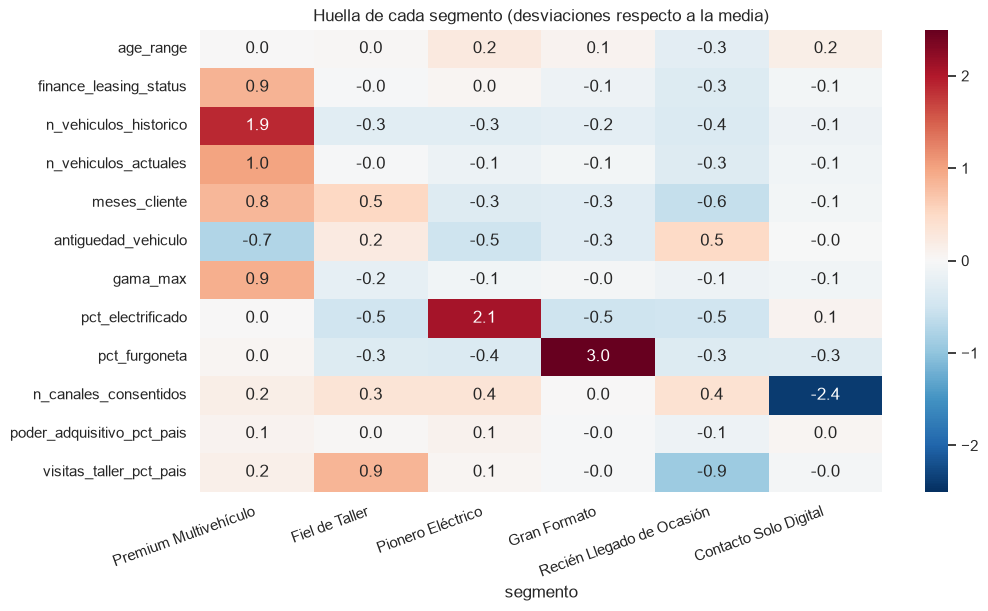

In [5]:
huella = X.groupby(clientes["segmento"], observed=True).mean().T[ORDEN]
plt.figure(figsize=(11, 6))
sns.heatmap(huella, cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, annot=True, fmt=".1f")
plt.title("Huella de cada segmento (desviaciones respecto a la media)")
plt.xticks(rotation=20, ha="right")
plt.show()

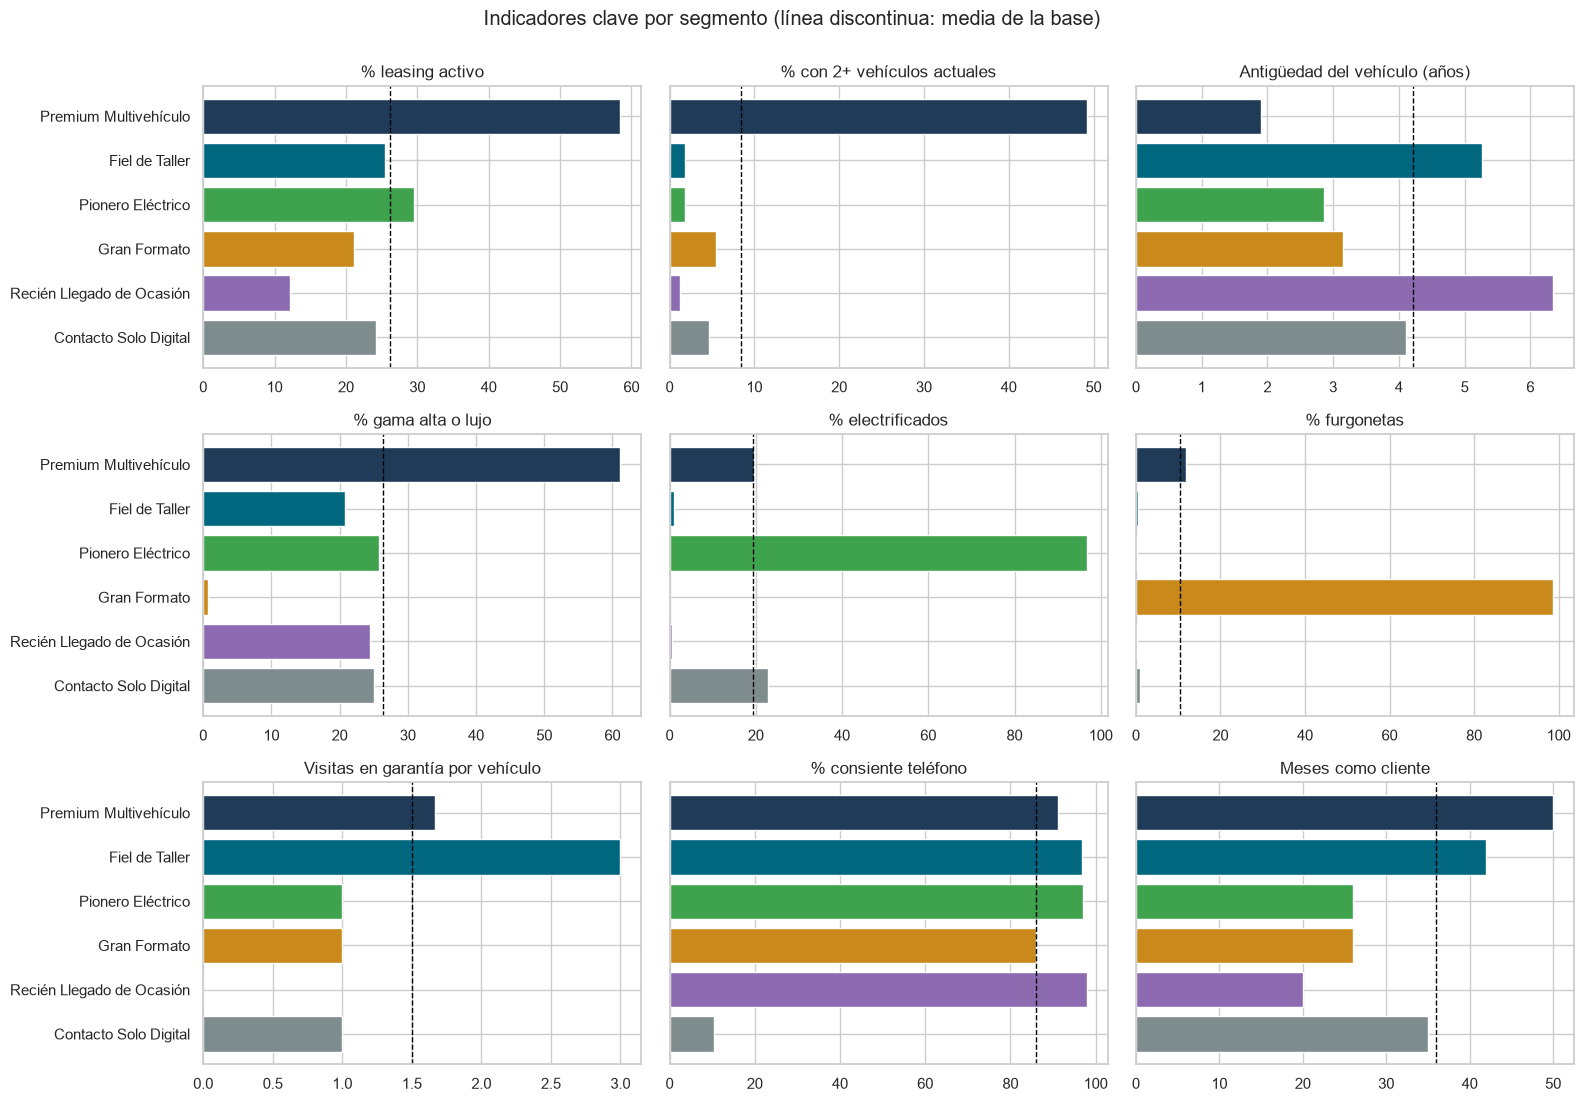

In [6]:
indicadores = {
    "% leasing activo": "% leasing activo",
    "% con 2+ vehículos actuales": "% con 2+ vehículos actuales",
    "antigüedad del vehículo (años, mediana)": "Antigüedad del vehículo (años)",
    "% gama alta o lujo (nivel 3-4)": "% gama alta o lujo",
    "% de vehículos electrificados": "% electrificados",
    "% de vehículos furgoneta": "% furgonetas",
    "visitas en garantía por vehículo (mediana)": "Visitas en garantía por vehículo",
    "% consiente teléfono": "% consiente teléfono",
    "meses como cliente (mediana)": "Meses como cliente",
}
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, (fila, titulo) in zip(axes.flat, indicadores.items()):
    vals = tabla.loc[fila, ORDEN].astype(float)
    ax.barh(ORDEN, vals, color=[COLORES[s] for s in ORDEN])
    ax.axvline(float(tabla.loc[fila, "TOTAL BASE"]), color="black", ls="--", lw=1)
    ax.invert_yaxis()
    ax.set_title(titulo)
    if ax not in axes[:, 0]:
        ax.set_yticklabels([])
fig.suptitle("Indicadores clave por segmento (línea discontinua: media de la base)", y=1.0)
plt.tight_layout()
plt.show()

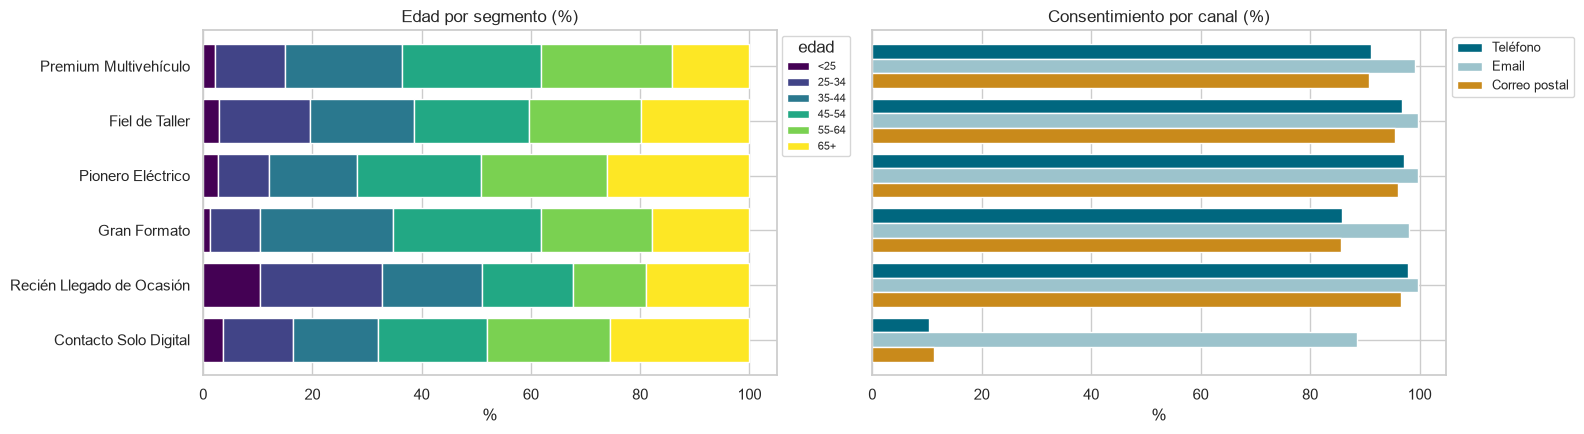

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
edad = pd.crosstab(clientes["segmento"], clientes["age_range"], normalize="index")[ORDEN_EDAD].mul(100)
edad.plot.barh(stacked=True, ax=axes[0], colormap="viridis", width=.8)
axes[0].invert_yaxis()
axes[0].set(title="Edad por segmento (%)", xlabel="%", ylabel="")
axes[0].legend(title="edad", bbox_to_anchor=(1, 1), fontsize=8)
canal = clientes.groupby("segmento", observed=True)[["consent_phone", "consent_email", "consent_post"]].mean().mul(100)
canal.columns = ["Teléfono", "Email", "Correo postal"]
canal.plot.barh(ax=axes[1], color=["#00677F", "#9cc3cc", "#c98a1b"], width=.8)
axes[1].invert_yaxis()
axes[1].set(title="Consentimiento por canal (%)", xlabel="%", ylabel="")
axes[1].set_yticklabels([])
axes[1].legend(bbox_to_anchor=(1, 1), fontsize=9)
plt.tight_layout()
plt.show()

In [8]:
# Modelos y motorización de los vehículos de cada segmento (todas sus relaciones)
veh = df[["client_id", "model_class", "engine_concept"]].merge(clientes[["segmento"]], left_on="client_id", right_index=True)
top_modelos = (veh.groupby("segmento", observed=True)["model_class"]
                  .apply(lambda s: ", ".join(f"{m} ({p:.0f} %)" for m, p in s.value_counts(normalize=True).mul(100).head(4).items())))
motor = pd.crosstab(veh["segmento"], veh["engine_concept"].fillna("UNKNOWN"), normalize="index").mul(100)
display(top_modelos.rename("modelos más frecuentes").to_frame())
motor[["COMBUSTION", "MILD_HYBRID", "PLUGIN_HYBRID", "ELECTRIC", "UNKNOWN"]].round(0)

,modelos más frecuentes
segmento,
Premium Multivehículo,"GLC-Class (13 %), V-Class / Vito (11 %), C-Cla..."
Fiel de Taller,"B-/GLA-/GLB-Class (18 %), GLC-Class (17 %), A-..."
Pionero Eléctrico,"GLC-Class (24 %), EQA-/EQB-Class (23 %), GLE-/..."
Gran Formato,"V-Class / Vito (69 %), Sprinter (20 %), Citan ..."
Recién Llegado de Ocasión,"A-Class (18 %), C-Class (18 %), GLC-Class (15 ..."
Contacto Solo Digital,"GLC-Class (19 %), C-Class (13 %), B-/GLA-/GLB-..."


engine_concept,COMBUSTION,MILD_HYBRID,PLUGIN_HYBRID,ELECTRIC,UNKNOWN
segmento,,,,,
Premium Multivehículo,32.0,8.0,7.0,7.0,46.0
Fiel de Taller,37.0,15.0,1.0,1.0,48.0
Pionero Eléctrico,2.0,1.0,35.0,33.0,29.0
Gran Formato,55.0,0.0,0.0,0.0,45.0
Recién Llegado de Ocasión,41.0,12.0,0.0,0.0,46.0
Contacto Solo Digital,29.0,11.0,8.0,8.0,43.0


## 3. Trampas de interpretación (comprobadas antes de poner nombres)

### 3.1 ¿Las visitas al taller reflejan al cliente o la edad de su coche?

En el Reto 1 vimos que las visitas en garantía dependen de la edad del coche: suben hasta ~5 años y luego bajan.
"Fiel de Taller" tiene coches de ~5 años (pico de visitas) y "Recién Llegado de Ocasión" coches de ~6 años (fuera de
garantía). Si la diferencia se debiera solo a eso, los nombres estarían mal. Comparamos **coches de la misma edad**.

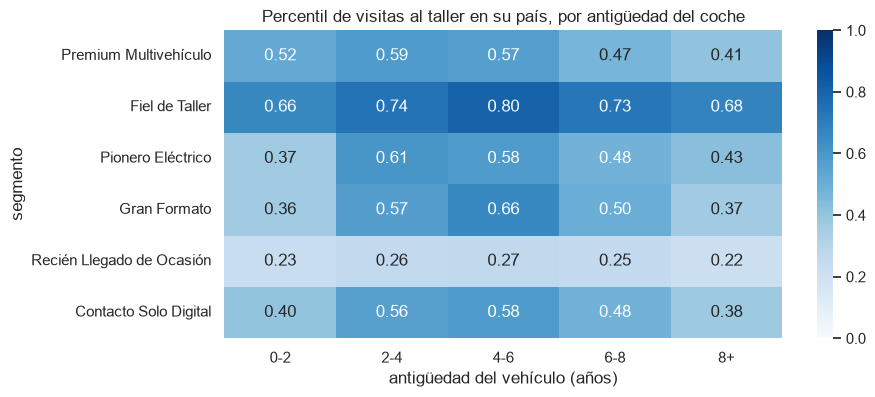

In [9]:
clientes["banda_antigüedad"] = pd.cut(clientes["antiguedad_vehiculo"], [-1, 2, 4, 6, 8, 50],
                                      labels=["0-2", "2-4", "4-6", "6-8", "8+"])
piv = clientes.pivot_table(index="segmento", columns="banda_antigüedad", values="visitas_taller_pct_pais",
                           aggfunc="mean", observed=True)
plt.figure(figsize=(9, 4))
sns.heatmap(piv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Percentil de visitas al taller en su país, por antigüedad del coche")
plt.xlabel("antigüedad del vehículo (años)")
plt.show()

**Resultado:** con coches de la **misma edad**, "Fiel de Taller" tiene más visitas en **todas** las bandas (percentil
0,66-0,80) y "Recién Llegado de Ocasión" menos en todas (0,22-0,27). La diferencia es de **comportamiento**, no de edad
del coche. Los nombres se sostienen.

### 3.2 "Recién Llegado de Ocasión": ¿segunda mano? (hipótesis)

Si el coche es bastante más antiguo que la relación del cliente con la marca, probablemente lo compró **usado**.

In [10]:
clientes["coche_anterior_a_la_relacion"] = clientes["antiguedad_vehiculo"] * 12 > clientes["meses_cliente"] + 12
(clientes.groupby("segmento", observed=True)["coche_anterior_a_la_relacion"].mean().mul(100)
   .rename("% con coche >1 año más antiguo que su relación con la marca").to_frame())

,% con coche >1 año más antiguo que su relación con la marca
segmento,
Premium Multivehículo,9.8
Fiel de Taller,50.4
Pionero Eléctrico,32.6
Gran Formato,37.9
Recién Llegado de Ocasión,81.2
Contacto Solo Digital,49.6


El **81 %** de este segmento tiene un coche más de un año anterior a su relación con la marca (10 % en Premium
Multivehículo). Junto con que casi nunca financian (85 %) y apenas usan el taller oficial, apunta a una **entrada por
el mercado de ocasión**.

⚠️ **Es una hipótesis.** `months_as_mb_customer` cuenta desde la **primera conexión** del cliente a un coche, no desde la
compra. Otra explicación posible: clientes que activaron tarde los servicios conectados. **Cómo validarlo:** cruzar con
el registro de ventas (nuevo / usado / concesionario) antes de lanzar campañas basadas en ello.

### 3.3 "Contacto Solo Digital": ¿son clientes no contactables?

In [11]:
seg_digital = clientes[clientes["segmento"] == "Contacto Solo Digital"]
pd.Series({
    "% solo email (1 canal = email)": ((seg_digital["n_canales_consentidos"] == 1) & seg_digital["consent_email"]).mean() * 100,
    "% con 0 canales": (seg_digital["n_canales_consentidos"] == 0).mean() * 100,
    "% consiente teléfono": seg_digital["consent_phone"].mean() * 100,
    "% consiente correo postal": seg_digital["consent_post"].mean() * 100,
}).round(1)

% solo email (1 canal = email)   78.6
% con 0 canales                   0.0
% consiente teléfono             10.4
% consiente correo postal        11.3
dtype: float64

No: el 89 % acepta **email** (el 79 % **solo** email) y ninguno tiene 0 canales; lo que falta es teléfono (10 %) y
correo postal (11 %). El resto de su perfil (edad, gama, vehículos,
taller) está **cerca de la media**: es un segmento de **canal**, no de tipo de cliente. Su valor para marketing es
operativo: a estos clientes solo se les puede llegar por email, así que cualquier campaña telefónica o postal los excluye.

### 3.4 Variables que NO diferencian a los segmentos

In [12]:
no_dif = pd.DataFrame({
    "percentil de poder adquisitivo (media)": clientes.groupby("segmento", observed=True)["poder_adquisitivo_pct_pais"].mean(),
    "distancia media por trayecto, km (mediana)": clientes.groupby("segmento", observed=True)["trip_distance_average"].median(),
    "velocidad media, km/h (mediana)": clientes.groupby("segmento", observed=True)["speed_average"].median(),
    "% con poder adquisitivo imputado": clientes.groupby("segmento", observed=True)["poder_adquisitivo_hab_eur"].apply(lambda s: s.isna().mean() * 100),
    "% con 36 meses exactos (artefacto)": clientes.groupby("segmento", observed=True)["meses_cliente"].apply(lambda s: (s == 36).mean() * 100),
    "% con telemetría*": clientes.groupby("segmento", observed=True)["tiene_telemetria"].mean() * 100,
})
no_dif.loc["TOTAL BASE"] = [clientes["poder_adquisitivo_pct_pais"].mean(), clientes["trip_distance_average"].median(),
                            clientes["speed_average"].median(), clientes["poder_adquisitivo_hab_eur"].isna().mean() * 100,
                            (clientes["meses_cliente"] == 36).mean() * 100, clientes["tiene_telemetria"].mean() * 100]
no_dif.round(2)

,percentil de poder adquisitivo (media),"distancia media por trayecto, km (mediana)","velocidad media, km/h (mediana)",% con poder adquisitivo imputado,% con 36 meses exactos (artefacto),% con telemetría*
segmento,,,,,,
Premium Multivehículo,0.5,14.6,49.7,1.9,11.7,73.6
Fiel de Taller,0.5,13.6,49.0,2.9,15.6,70.9
Pionero Eléctrico,0.5,13.6,49.5,11.9,5.5,62.5
Gran Formato,0.5,15.6,51.4,14.6,7.8,61.3
Recién Llegado de Ocasión,0.5,14.2,48.9,14.8,13.2,51.8
Contacto Solo Digital,0.5,14.2,50.0,8.1,14.6,33.7
TOTAL BASE,0.5,14.1,49.4,8.8,12.2,60.0


- **Poder adquisitivo de la zona**: igual en todos los segmentos (≈ 0,5, la mediana). El carácter premium de un
  segmento viene de **lo que conduce** (gama, AMG), no de dónde vive. No se debe vender "Premium Multivehículo" como
  "zonas ricas".
- **Conducción** (km por trayecto, velocidad): prácticamente igual en todos. La telemetría no habría ayudado a segmentar.
- **Poder adquisitivo imputado**: oscila entre el 2 % y el 15 % según el segmento. En los segmentos con más imputados
  (Recién Llegado, Gran Formato, Pionero Eléctrico) la media está algo "comprimida" hacia 0,5.
- **Artefacto de 36 meses** (Reto 1): está repartido (6-16 %) y no domina ningún segmento.
- *Telemetría: solo descriptiva y sesgada (los eléctricos no la tienen); no se usa para interpretar.

### 3.5 Género: precaución

El género es **inferido** y desconocido en un 4-29 % según el segmento (29 % en Recién Llegado de Ocasión). Las
diferencias de género entre segmentos **no se usan para definir campañas**: solo "Premium Multivehículo" destaca
(81 % hombre, con solo un 4 % desconocido).

## 4. Sub-perfiles de "Premium Multivehículo"

En el Reto 3 este fue el segmento menos cohesionado (silhouette 0,05, 40 % de clientes en la frontera). Por dentro
mezcla tres situaciones: varios coches a la vez, leasing activo y flotas.

In [13]:
prem = clientes["segmento"] == "Premium Multivehículo"
cp = clientes[prem]
multi, leasing = cp["n_vehiculos_actuales"] >= 2, cp["finance_leasing_status"].str.startswith("active")
pd.Series({
    "solo multivehículo (2+ actuales, sin leasing)": (multi & ~leasing).mean() * 100,
    "solo leasing activo (<2 actuales)": (~multi & leasing).mean() * 100,
    "multivehículo y leasing": (multi & leasing).mean() * 100,
    "ninguno de los dos (histórico amplio)": (~multi & ~leasing).mean() * 100,
    "flota (>10 vehículos en el histórico)": (cp["n_vehiculos_historico"] > 10).mean() * 100,
}, name="% del segmento").round(1).to_frame()

,% del segmento
"solo multivehículo (2+ actuales, sin leasing)",23.5
solo leasing activo (<2 actuales),32.8
multivehículo y leasing,25.7
ninguno de los dos (histórico amplio),18.0
flota (>10 vehículos en el histórico),7.5


Para separarlo con criterio, aplicamos un **K-Means solo dentro de este segmento** (mismas features, mismo
preprocesado), con 50 inicializaciones, y comparamos k = 2 a 5.

In [14]:
Xp = X[prem]
sub_res = {}
for k in range(2, 6):
    m = KMeans(n_clusters=k, n_init=N_INIT_FINAL, random_state=SEMILLA).fit(Xp)
    otra = KMeans(n_clusters=k, n_init=N_INIT_FINAL, random_state=7).fit_predict(Xp)
    sub_res[k] = {"silhouette": f"{silhouette_score(Xp, m.labels_, sample_size=15_000, random_state=0):.3f}",
                  "ARI entre semillas": f"{adjusted_rand_score(m.labels_, otra):.3f}",
                  "tamaños (%)": " / ".join(f"{p:.0f}" for p in np.bincount(m.labels_) / len(Xp) * 100)}
    if k == 3:
        sub_km = m
pd.DataFrame(sub_res).T

,silhouette,ARI entre semillas,tamaños (%)
2,0.227,0.999,23 / 77
3,0.162,1.000,16 / 50 / 34
4,0.168,1.000,12 / 50 / 30 / 8
5,0.116,0.998,25 / 29 / 26 / 8 / 12


- **k = 2** tiene el mejor silhouette (0,23), pero junta a los clientes en leasing con los que compran al contado, dos
  públicos que piden ofertas distintas.
- **k = 3** (silhouette 0,16, más del triple que el del segmento completo, y totalmente estable entre semillas)
  separa tres sub-perfiles con una acción comercial distinta.
- **k = 4** tiene un silhouette prácticamente igual (0,168), pero crea un sub-grupo del 8 % del segmento (~1.800
  clientes), demasiado pequeño para una campaña propia. A partir de k = 5 el silhouette cae.

**Elegimos k = 3**, con el mismo criterio de accionabilidad del Reto 3.

In [15]:
cen_sub = pd.DataFrame(sub_km.cluster_centers_, columns=X.columns)
nombres_sub = {cen_sub["n_vehiculos_historico"].idxmax(): "Gran Cuenta / Flota"}
resto_sub = cen_sub.drop(index=list(nombres_sub))
nombres_sub[resto_sub["finance_leasing_status"].idxmax()] = "Renovador en Leasing"
nombres_sub[resto_sub["finance_leasing_status"].idxmin()] = "Premium al Contado"
cp = cp.assign(subperfil=pd.Series(sub_km.labels_, index=cp.index).map(nombres_sub))
ORDEN_SUB = ["Renovador en Leasing", "Premium al Contado", "Gran Cuenta / Flota"]

def perfil_sub(g):
    return pd.Series({
        "% del segmento": len(g) / len(cp) * 100,
        "clientes": len(g),
        "% leasing activo": g["finance_leasing_status"].str.startswith("active").mean() * 100,
        "vehículos en el histórico (mediana)": g["n_vehiculos_historico"].median(),
        "vehículos actuales (mediana)": g["n_vehiculos_actuales"].median(),
        "% gama alta o lujo": (g["gama_max"] >= 3).mean() * 100,
        "% con algún AMG": (g["pct_amg"] > 0).mean() * 100,
        "% de vehículos furgoneta": g["pct_furgoneta"].mean() * 100,
        "% con relación B2B": g["es_b2b"].mean() * 100,
        "antigüedad del vehículo (mediana)": g["antiguedad_vehiculo"].median(),
        "meses como cliente (mediana)": g["meses_cliente"].median(),
        "% 45 años o más": g["age_range"].isin(["45-54", "55-64", "65+"]).mean() * 100,
    })
cp.groupby("subperfil").apply(perfil_sub).T[ORDEN_SUB]

subperfil,Renovador en Leasing,Premium al Contado,Gran Cuenta / Flota
% del segmento,50.3,34.2,15.6
clientes,"11,210.0","7,621.0","3,473.0"
% leasing activo,98.3,0.2,57.7
vehículos en el histórico (mediana),2.0,3.0,8.0
vehículos actuales (mediana),1.0,2.0,3.0
% gama alta o lujo,48.1,74.4,74.4
% con algún AMG,32.3,36.5,48.1
% de vehículos furgoneta,6.4,9.9,33.5
% con relación B2B,0.4,1.3,7.7
antigüedad del vehículo (mediana),1.8,2.5,0.9


## 5. Fichas de segmento para marketing

Las cifras de cada ficha salen de la tabla del apartado 2.2.

---

### 🔷 Premium Multivehículo · 12,9 % (22.304 clientes)
**Quién es:** el cliente de **mayor valor**. Mediana de 3 Mercedes en su historia, la mitad con 2 o más a la vez, un
58,5 % con leasing activo, coches muy nuevos (mediana < 2 años), un 61 % con gama alta o lujo y un 36 % con algún AMG.
Es el más antiguo como cliente (50 meses) y casi nunca está inactivo (2 %).
**Sub-perfiles:** *Renovador en Leasing* (~50 %), *Premium al Contado* (~34 %) y *Gran Cuenta / Flota* (~16 %).
- **Oferta de vehículos:** renovación anticipada antes del fin del leasing (Renovador); preestrenos de gama alta y AMG
  (Al Contado); condiciones de flota y furgonetas (Gran Cuenta).
- **Mantenimiento:** paquetes multi-vehículo con un único contrato.
- **Fidelización:** programa de cliente preferente, eventos de marca.
- **Comunicación:** gestor personal; todos los canales disponibles (teléfono 91 %).

### 🔷 Fiel de Taller · 26,2 % (45.449 clientes)
**Quién es:** el segmento más grande junto con Recién Llegado. Cliente veterano (42 meses) con un coche, casi siempre
compacto o medio (A, B/GLA/GLB, C, GLC), de combustión y de unos 5 años. Su rasgo distintivo: **usa el taller oficial
mucho más que la media** de su país, también comparando coches de la misma edad. Más presente en Suiza (74 %).
- **Oferta de vehículos:** su coche entra en edad de renovación (37 % con 6+ años). Ofertas de cambio con valoración
  de su coche actual.
- **Mantenimiento:** **público principal** de los planes de mantenimiento y de la garantía extendida, porque su
  garantía está terminando.
- **Fidelización:** convertir la confianza en el taller en fidelidad de compra.
- **Comunicación:** teléfono (97 %) y correo postal (96 %); el taller como punto de contacto.

### 🔷 Pionero Eléctrico · 14,3 % (24.754 clientes)
**Quién es:** el 97 % de sus vehículos son **híbridos enchufables o eléctricos** (EQA/EQB, GLC híbrido, EQC, EQE…). Coches
muy nuevos (mediana 2,9 años), cliente reciente (26 meses) y con más peso de Austria (45 %, frente al 34 % de la base).
Un 30 % tiene leasing activo.
- **Oferta de vehículos:** nuevas gamas EQ, paso de híbrido enchufable a 100 % eléctrico.
- **Mantenimiento:** planes específicos de batería y software.
- **Fidelización:** servicios de carga, actualizaciones remotas.
- **Comunicación:** digital y teléfono (97 %).

### 🔷 Gran Formato · 8,8 % (15.183 clientes)
**Quién es:** casi todos sus vehículos son **furgonetas**: V-Class/Vito (69 %), Sprinter (20 %) y Citan (7 %). Coches
nuevos (3 años) y combustión. Pese a ser furgonetas, solo el 3 % son relaciones de empresa: son mayoritariamente
**particulares** (familias numerosas, ocio, autónomos registrados como particulares).
- **Oferta de vehículos:** nuevas V-Class y eVito/eSprinter; versiones camper.
- **Mantenimiento:** planes con vehículo de sustitución (para ellos la furgoneta suele ser imprescindible).
- **Fidelización:** accesorios y equipamiento.
- **Comunicación:** teléfono (86 %) y correo postal (86 %), algo por debajo del resto.

### 🔷 Recién Llegado de Ocasión · 27,1 % (46.920 clientes)
**Quién es:** el cliente **más reciente** (20 meses) y el de **perfil más joven** (33 % menores de 35, frente al ~20 % de
la base), aunque la mitad tiene 45 años o más. Coche **antiguo** (mediana 6,3 años; el 54 % con 6+ años), casi nunca ha
financiado (85 %), **no usa el taller oficial** (mediana de 0 visitas) y un 18 % ya no tiene vehículo conectado.
Hipótesis: **entró en la marca con un coche de ocasión** (ver 3.2).
- **Oferta de vehículos:** **primer Mercedes nuevo** o seminuevo certificado, con financiación de entrada.
- **Mantenimiento:** atraerlo al taller oficial con una primera revisión o un diagnóstico gratuitos.
- **Fidelización:** es el segmento con **mayor riesgo de abandono** (18 % inactivos). Bienvenida y onboarding.
- **Comunicación:** teléfono (98 %) y postal (97 %). Atención: un 29 % sin género conocido y un 15 % sin dato de zona.

### 🔷 Contacto Solo Digital · 10,9 % (18.846 clientes)
**Quién es:** su perfil de cliente está **en la media** (edad, gama, vehículos), pero acepta muy pocos canales: el 79 %
**solo email** (email 89 %, teléfono 10 %, postal 11 %). Es un segmento de **canal**: indica *cómo* se puede contactar, no *qué* ofrecer.
- **Acción prioritaria:** campañas de **recaptación de consentimiento** (por email y en el taller o el concesionario).
- **Comunicación:** sobre todo email y app. Cualquier campaña por teléfono o correo postal no llega a este 11 % de
  la base.
- **Oferta y mantenimiento:** según su vehículo (un 23 % de sus coches son electrificados), con las ofertas del segmento
  al que más se parezca.

## 6. Salud y seguridad vial por segmento (datos externos)

En el notebook **Extra_SaludSeguridadVial** se construyó, con datos **oficiales** de Austria y Suiza, una tabla por
código postal (`datos_externos_por_cp.csv`) con cuatro indicadores de la **zona** donde vive el cliente. Desde el
Reto 2, `features.py` los une a cada cliente como columnas de perfilado:

| Indicador | Fuente | Austria | Suiza |
|---|---|---|---|
| Accidentes con heridos por 1.000 hab./año (sin autopistas) | Statistik Austria 2025 / ASTRA 2021-2025 | distrito | municipio |
| % de accidentes con fallecidos o heridos graves | ídem | distrito | municipio |
| Mortalidad estandarizada por edad (‰, 2023-2025) | Statistik Austria | distrito | no se publica |
| Distancia en línea recta al hospital general de agudos (km) | Ministerio de Sanidad AT / BAG | municipio | código postal |

Enlaces exactos, periodos y condiciones de uso de cada fuente: [`Fuentes_Datos_Externos.md`](Fuentes_Datos_Externos.md).

Aquí se responde a dos preguntas:
1. **¿Viven los segmentos en zonas distintas?** (apartado 6): perfil de zona de cada segmento.
2. **¿Cambian los segmentos si el K-Means usa estas variables?** (apartado 7).

Detalles que hay que cuidar:
- **Siempre dentro de cada país.** Suiza tiene la mitad de accidentes por habitante que Austria y hospitales más
  cercanos: comparar segmentos con distinta mezcla de países confundiría país con segmento (el error del Reto 2).
- **Son datos de zona, no de la persona**: todos los clientes de un mismo distrito comparten el valor.
- Por eso, los clientes de una misma zona **no son observaciones independientes**: con 170.000 clientes cualquier
  diferencia mínima saldría "significativa" en un test clásico. La incertidumbre se mide con un **bootstrap por
  zonas** (se remuestrean distritos o municipios enteros, no clientes).

In [16]:
# Los indicadores de zona ya vienen en `clientes`: features.py los une por país + código postal (Reto 2, apartado 7)
IND = {"tasa_accidentes": "Accidentes / 1.000 hab.", "pct_graves": "% accidentes graves",
       "mortalidad_std": "Mortalidad estandarizada (‰)", "dist_hospital_km": "Distancia al hospital (km)"}
print("% de clientes con dato de zona:")
clientes.groupby("country_code")[list(IND)].apply(lambda g: g.notna().mean() * 100).round(1)

% de clientes con dato de zona:


,tasa_accidentes,pct_graves,mortalidad_std,dist_hospital_km
country_code,,,,
AT,88.0,88.0,88.0,87.9
CH,89.8,89.8,0.0,92.8


Sin dato quedan los clientes **sin código postal** (Reto 1) y, en Suiza, los de municipios de menos de 1.000
habitantes (tasa demasiado ruidosa). La mortalidad solo existe para Austria. "Recién Llegado de Ocasión" es el
segmento con más clientes sin código postal (~15 %, ver su ficha en el apartado 5).

### 6.1 Perfil de zona de cada segmento

Valor medio del indicador entre los clientes de cada segmento, por país. La fila **TOTAL** es la media de todos los
clientes de ese país.

In [17]:
perfil_zona = {}
for pais in ["AT", "CH"]:
    s = clientes[clientes["country_code"] == pais]
    t = s.groupby("segmento", observed=True)[list(IND)].mean().reindex(ORDEN)
    t.loc["TOTAL"] = s[list(IND)].mean()
    perfil_zona[pais] = t.rename(columns=IND)
pd.concat(perfil_zona, axis=1).dropna(axis=1, how="all").map("{:.2f}".format)

AT                                                                                                  CH                                               
                          Accidentes / 1.000 hab. % accidentes graves Mortalidad estandarizada (‰) Distancia al hospital (km) Accidentes / 1.000 hab. % accidentes graves Distancia al hospital (km)
segmento                                                                                                                                                                                            
Premium Multivehículo                        4.21               17.26                         8.86                       7.68                    1.65               23.32                       4.17
Fiel de Taller                               4.08               16.72                         8.93                       7.20                    1.67               23.01                       3.91
Pionero Eléctrico                            4.15               17.24                         8.88                       7.74                    1.66               23.61                       4.11
Gran Formato                                 4.17               18.42                         8.82                       8.83                    1.69               23.82                       4.92
Recién Llegado de Ocasión                    3.98               16.48                         8.97                       6.99                    1.69               22.81                       4.01
Contacto Solo Digital                        4.07               16.81                         8.94                       7.30                    1.66               23.31                       4.21
TOTAL                                        4.09               17.00                         8.91                       7.48                    1.67               23.16                       4.10

Para comparar de un vistazo se expresa como **índice: 100 = media de su país**. Un 118 significa que los clientes del
segmento viven en zonas con un valor un 18 % superior al cliente medio de su país. Entre corchetes, el **intervalo de
confianza del 95 %** del bootstrap por zonas (500 remuestreos).

In [18]:
def indice_bootstrap(pais, col, B=500, semilla=0):
    s = clientes[(clientes["country_code"] == pais) & clientes[col].notna()]
    # Sumas y recuentos por zona y segmento: remuestrear zonas = dar a cada zona un peso (nº de veces que sale)
    suma = s.pivot_table(index="zona", columns="segmento", values=col, aggfunc="sum", observed=True).reindex(columns=ORDEN).fillna(0)
    n = s.pivot_table(index="zona", columns="segmento", values=col, aggfunc="size", observed=True).reindex(columns=ORDEN).fillna(0)
    def indice(w):
        seg = (w @ suma.values) / (w @ n.values)
        return seg / ((w @ suma.values.sum(1)) / (w @ n.values.sum(1))) * 100
    rng = np.random.default_rng(semilla)
    pesos = rng.multinomial(len(suma), np.full(len(suma), 1 / len(suma)), size=B)
    boot = np.array([indice(w) for w in pesos])
    return pd.DataFrame({"índice": indice(np.ones(len(suma))), "ic_inf": np.percentile(boot, 2.5, axis=0),
                         "ic_sup": np.percentile(boot, 97.5, axis=0)}, index=ORDEN)

idx_zona = {(pais, col): indice_bootstrap(pais, col) for pais in ["AT", "CH"] for col in IND
            if clientes.loc[clientes["country_code"] == pais, col].notna().any()}
tabla_idx = pd.DataFrame({f"{pais} · {IND[col]}": r.apply(lambda f: f"{f['índice']:.0f} [{f['ic_inf']:.0f}-{f['ic_sup']:.0f}]", axis=1)
                          for (pais, col), r in idx_zona.items()})
tabla_idx

,AT · Accidentes / 1.000 hab.,AT · % accidentes graves,AT · Mortalidad estandarizada (‰),AT · Distancia al hospital (km),CH · Accidentes / 1.000 hab.,CH · % accidentes graves,CH · Distancia al hospital (km)
Premium Multivehículo,103 [101-105],102 [100-103],99 [99-100],103 [99-107],99 [97-100],101 [99-102],102 [100-104]
Fiel de Taller,100 [99-100],98 [97-99],100 [100-100],96 [94-98],100 [99-101],99 [99-100],95 [94-97]
Pionero Eléctrico,102 [100-104],101 [101-102],100 [99-100],104 [101-106],99 [98-101],102 [101-103],100 [98-103]
Gran Formato,102 [99-105],108 [106-112],99 [99-99],118 [112-125],101 [99-104],103 [101-105],120 [116-124]
Recién Llegado de Ocasión,97 [95-99],97 [96-98],101 [100-101],93 [90-97],101 [100-102],98 [97-99],98 [96-100]
Contacto Solo Digital,100 [98-101],99 [98-100],100 [100-101],98 [94-100],99 [98-101],101 [99-102],103 [100-106]


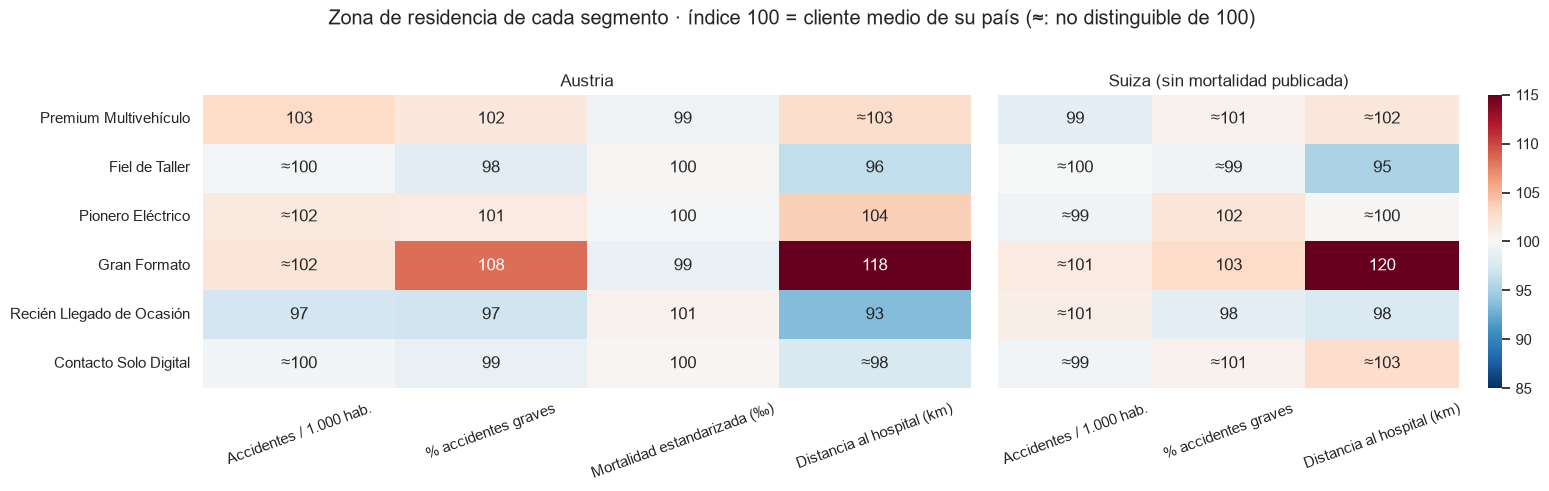

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [4, 3]})
for ax, pais in zip(axes, ["AT", "CH"]):
    mat = pd.DataFrame({IND[col]: r["índice"] for (p, col), r in idx_zona.items() if p == pais})
    # Celdas cuyo intervalo de confianza incluye el 100 → se marcan con "≈" (no distinguible de la media)
    sig = pd.DataFrame({IND[col]: (r["ic_inf"] > 100) | (r["ic_sup"] < 100) for (p, col), r in idx_zona.items() if p == pais})
    etiquetas = mat.round(0).astype(int).astype(str).where(sig, "≈" + mat.round(0).astype(int).astype(str))
    sns.heatmap(mat, annot=etiquetas, fmt="", cmap="RdBu_r", center=100, vmin=85, vmax=115, ax=ax,
                cbar=pais == "CH", yticklabels=pais == "AT")
    ax.set_title({"AT": "Austria", "CH": "Suiza (sin mortalidad publicada)"}[pais])
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Zona de residencia de cada segmento · índice 100 = cliente medio de su país (≈: no distinguible de 100)", y=1.02)
plt.tight_layout()
plt.show()

**Lectura:**
- **Las diferencias entre segmentos son pequeñas** (índices entre ~90 y ~120). Era lo esperable: en el Reto 4 (3.4) ya
  vimos que el poder adquisitivo de la zona tampoco diferencia segmentos. Los segmentos se definen por **qué conduce y
  cómo se relaciona** el cliente con la marca, no por dónde vive.
- **Gran Formato es la excepción clara**: vive **un 18-20 % más lejos del hospital** que el cliente medio, en los
  **dos países** (intervalos que no tocan el 100), y en Austria en zonas con **más accidentes graves** (índice ~108). Es
  el perfil rural / de montaña: familias numerosas y autónomos con furgoneta fuera de las ciudades.
- **Recién Llegado de Ocasión** es el más **urbano**: más cerca del hospital y con menos accidentes graves. En Austria
  es el de **mortalidad de zona más alta**, aunque la diferencia es mínima (8,97 frente a 8,91 ‰): coincide con la
  correlación entre zonas del notebook Extra (ρ = +0,46), pero a nivel de segmento casi no se nota.
- **Pionero Eléctrico** vive algo más lejos del hospital en Austria (104) y en zonas con algo más de accidentes graves
  en ambos países (101-102): periferias y zonas residenciales con casa y cargador propio. Premium Multivehículo tiene
  un 103 similar, pero su intervalo toca el 100.
- **Fiel de Taller y Contacto Solo Digital**: en la media en todo.
- La **tasa de accidentes por habitante** no diferencia ningún segmento: además, es el indicador más ruidoso (distritos
  turísticos o de paso, con accidentes de no residentes).

### 6.2 Cruce segmento × zona: públicos de seguridad vial

Que los segmentos se parezcan en su zona **no quiere decir que la zona no sirva**: la diferencia está **dentro** de
cada segmento. El segmento dice **qué ofrecer**; la zona dice **a quién de ese segmento** priorizar con un mensaje de
seguridad. Para cada segmento se cuentan los clientes que:
- viven en una zona del **25 % con más accidentes graves de su país**;
- de ellos, tienen un **coche de referencia anterior a julio de 2024** (sin los asistentes obligatorios del
  Reglamento General de Seguridad de la UE desde esa fecha: frenada de emergencia, aviso de cambio de carril...);
- viven en el **10 % más alejado del hospital** de su país.

Los cortes son percentiles **entre clientes**, dentro de cada país. Como todos los clientes de una zona comparten el
valor, hay empates y el "25 %" real queda en un ~22 %.

In [20]:
fecha_ref = pd.to_datetime(df["date_of_first_registration"], errors="coerce").max()
umbral_gsr2 = (fecha_ref - pd.Timestamp("2024-07-07")).days / 365.25   # antigüedad que tenía un coche matriculado ese día
clientes["zona_grave"] = clientes["pct_graves_pct_pais"] >= .75
clientes["coche_pre_gsr2"] = clientes["antiguedad_vehiculo"] > umbral_gsr2
clientes["lejos_hospital"] = clientes["dist_hospital_km_pct_pais"] >= .9

publicos_seg = clientes.groupby("segmento", observed=True).apply(lambda g: pd.Series({
    "clientes": len(g),
    "zona de accidentes graves (Q4)": g["zona_grave"].sum(),
    "% del segmento": g["zona_grave"].mean() * 100,
    "…y coche anterior a jul-2024": (g["zona_grave"] & g["coche_pre_gsr2"]).sum(),
    "lejos del hospital (D10)": g["lejos_hospital"].sum(),
    "% del segmento ": g["lejos_hospital"].mean() * 100,
    "…y 65 años o más": (g["lejos_hospital"] & g["age_range"].eq("65+")).sum(),
})).reindex(ORDEN)
publicos_seg.loc["TOTAL"] = publicos_seg.sum()
publicos_seg.loc["TOTAL", "% del segmento"] = clientes["zona_grave"].mean() * 100
publicos_seg.loc["TOTAL", "% del segmento "] = clientes["lejos_hospital"].mean() * 100
publicos_seg.astype(object).apply(lambda c: c.map("{:.1f}".format) if c.name.startswith("%") else c.map("{:,.0f}".format))

,clientes,zona de accidentes graves (Q4),% del segmento,…y coche anterior a jul-2024,lejos del hospital (D10),% del segmento,…y 65 años o más
segmento,,,,,,,
Premium Multivehículo,"22,304","5,492",24.6,"2,241","2,156",9.7,298
Fiel de Taller,"45,449","10,571",23.3,"9,464","4,039",8.9,889
Pionero Eléctrico,"24,754","5,686",23.0,"3,613","2,158",8.7,528
Gran Formato,"15,183","3,604",23.7,"2,404","1,833",12.1,201
Recién Llegado de Ocasión,"46,920","9,292",19.8,"7,526","3,856",8.2,497
Contacto Solo Digital,"18,846","4,121",21.9,"2,973","1,745",9.3,432
TOTAL,"173,456","38,766",22.3,"28,221","15,787",9.1,"2,845"


**Acción Mercedes-Benz por segmento** (oferta del segmento + mensaje de seguridad para el público de su zona):

| Segmento | Qué dice la zona | Acción para el público de zona de riesgo |
|---|---|---|
| Gran Formato | Más lejos del hospital y, en Austria, más accidentes graves | Renovación a V-Class/Vito/Sprinter actuales con **Active Brake Assist**, **Asistente de viento lateral** y **4MATIC**; **llamada de emergencia** de Mercedes me connect / Mercedes PRO |
| Recién Llegado de Ocasión | Urbano, coche más antiguo | Los ~7.500 en zona grave con coche anterior a jul-2024: **seminuevo Mercedes-Benz Certified** o primer coche nuevo con asistentes de serie; **revisión de seguridad** gratuita en el taller oficial (frenos, neumáticos) como puerta de entrada |
| Fiel de Taller | En la media | Su coche entra en edad de renovación: en zona grave, destacar **PRE-SAFE®** y **Active Brake Assist** en la oferta de cambio; revisión de seguridad dentro del plan de mantenimiento |
| Premium Multivehículo | Prácticamente en la media | Paquetes de asistencia a la conducción (**DISTRONIC**, **Active Steering Assist**) en la renovación del leasing |
| Pionero Eléctrico | Algo más lejos del hospital (AT) y algo más de accidentes graves | Coches ya nuevos: seguridad vía **actualizaciones remotas** y servicios conectados |
| Contacto Solo Digital | En la media | Solo email: mensaje de seguridad dentro de las comunicaciones digitales |

**Uso responsable:** el dato de zona decide **dónde y qué** comunicar, nunca a quién excluir ni qué precio cobrar. Los
mensajes son positivos ("más seguridad para tus trayectos") y **nunca** mencionan la salud o la siniestralidad de la
zona del cliente.

## 7. ¿Y si metemos las variables de zona en el K-Means?

Alternativa: añadir los indicadores de zona como **features** del modelo y ver si aparecen segmentos nuevos. Decisiones:
- Se usan **accidentes, % graves y distancia al hospital**, como **percentil dentro de su país** (igual que el poder
  adquisitivo y las visitas al taller del Reto 2), escalados igual que el resto.
- **La mortalidad queda fuera**: solo existe en Austria. Imputarla al 66 % suizo de la base con la mediana crearía una
  variable casi constante en Suiza que separaría por país.
- Los clientes sin dato de zona (~10 %) se imputan con la **mediana** (como en el pipeline del Reto 2).
- Mismo K-Means que el Reto 3: k = 6, 50 inicializaciones, semilla 42.

In [21]:
COLS_ZONA_MODELO = ["tasa_accidentes", "pct_graves", "dist_hospital_km"]
Z = clientes[[f"{c}_pct_pais" for c in COLS_ZONA_MODELO]].copy()
Z = Z.fillna(Z.median())
Z = (Z - Z.mean()) / Z.std(ddof=0)
X_zona = pd.concat([X, Z], axis=1)

km_zona = ajustar_kmeans(X_zona)
km_zona_7 = KMeans(n_clusters=6, n_init=N_INIT_FINAL, random_state=7).fit(X_zona)
muestra = np.random.default_rng(0).choice(len(X), 20_000, replace=False)
pd.Series({
    "ARI con el modelo actual (1 = mismos segmentos)": adjusted_rand_score(km.labels_, km_zona.labels_),
    "ARI entre semillas del modelo con zona": adjusted_rand_score(km_zona.labels_, km_zona_7.labels_),
    "silhouette modelo actual (12 features)": silhouette_score(X.iloc[muestra], km.labels_[muestra]),
    "silhouette modelo con zona (15 features)": silhouette_score(X_zona.iloc[muestra], km_zona.labels_[muestra]),
}).map("{:.3f}".format).to_frame("valor")

,valor
ARI con el modelo actual (1 = mismos segmentos),0.978
ARI entre semillas del modelo con zona,0.994
silhouette modelo actual (12 features),0.136
silhouette modelo con zona (15 features),0.102


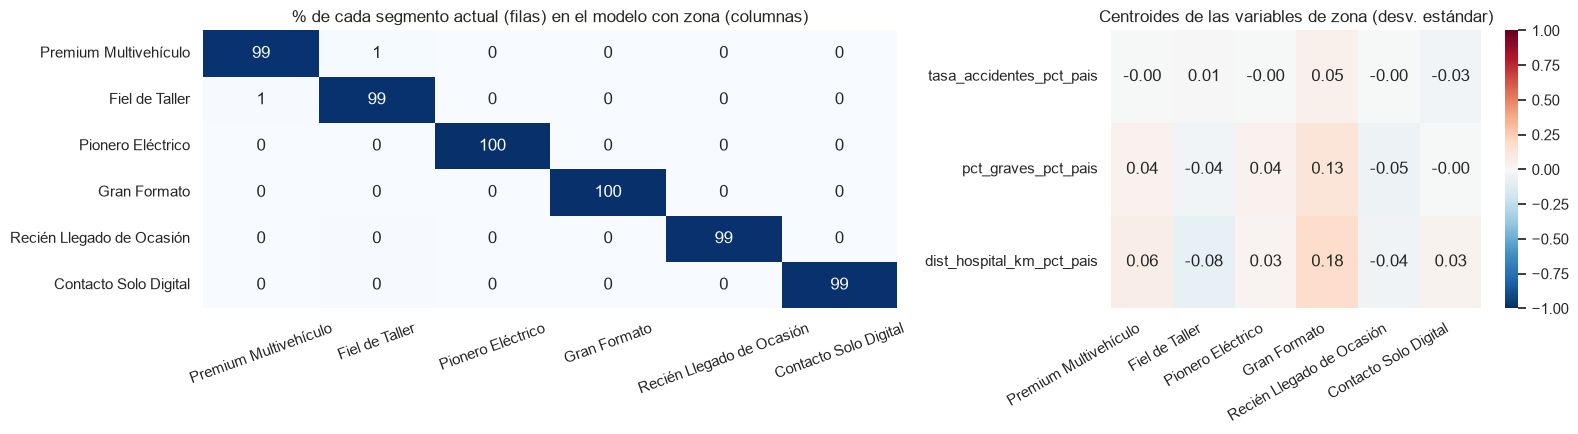

In [22]:
cen_zona = pd.DataFrame(km_zona.cluster_centers_, columns=X_zona.columns)
nombres_zona = nombrar_segmentos(cen_zona)
cen_zona.index = cen_zona.index.map(nombres_zona)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 2]})
cruce = pd.crosstab(clientes["segmento"], pd.Series(km_zona.labels_, index=clientes.index).map(nombres_zona),
                    normalize="index").reindex(index=ORDEN, columns=ORDEN) * 100
sns.heatmap(cruce, annot=True, fmt=".0f", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set(title="% de cada segmento actual (filas) en el modelo con zona (columnas)", xlabel="", ylabel="")
axes[0].tick_params(axis="x", rotation=20)
sns.heatmap(cen_zona.loc[ORDEN, Z.columns].T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set(title="Centroides de las variables de zona (desv. estándar)", xlabel="")
plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Resultado con el mismo peso que el resto de features:** salen **los mismos 6 segmentos** (ARI ≈ 0,98, el 99 % de cada
segmento cae en su equivalente). Las variables de zona apenas se mueven en los centroides (todas por debajo de ±0,2
desviaciones; la mayor, Gran Formato en distancia al hospital, la misma señal del apartado 6). El K-Means **las
ignora** porque no forman grupos, y solo añaden ruido: el **silhouette baja** de 0,136 a ~0,10.

### 7.1 ¿Y si se fuerza a la zona a pesar más?

Dos formas de forzarlo: dar **el doble de peso** a las variables de zona, o pedir **más clusters** (k = 8) para que
haya sitio para un grupo geográfico.

In [23]:
km_peso2 = KMeans(n_clusters=6, n_init=20, random_state=SEMILLA).fit(pd.concat([X, Z * 2], axis=1))
km_k8 = KMeans(n_clusters=8, n_init=20, random_state=SEMILLA).fit(X_zona)
forzados = {}
for nombre, modelo, cols in [("zona con peso doble (k = 6)", km_peso2, list(X.columns) + list(Z.columns)),
                             ("mismo peso, k = 8", km_k8, X_zona.columns)]:
    c = pd.DataFrame(modelo.cluster_centers_, columns=cols)
    forzados[nombre] = {
        "ARI con el modelo actual": adjusted_rand_score(km.labels_, modelo.labels_),
        "mayor |centroide| en variables de zona": c[Z.columns].abs().max().max(),
        "mayor |centroide| en furgonetas": c["pct_furgoneta"].abs().max(),
        "mayor |centroide| en electrificados": c["pct_electrificado"].abs().max(),
    }
pd.DataFrame(forzados).map("{:.2f}".format)

,zona con peso doble (k = 6),"mismo peso, k = 8"
ARI con el modelo actual,0.02,0.60
mayor |centroide| en variables de zona,2.43,0.18
mayor |centroide| en furgonetas,0.13,3.02
mayor |centroide| en electrificados,0.06,2.11


- **Con peso doble** la zona **se come el modelo**: ARI ≈ 0,02 con los segmentos actuales. Los clusters pasan a ser
  "urbano con muchos accidentes", "rural lejos del hospital"... y desaparecen furgonetas, eléctricos, leasing y taller,
  que eran lo accionable. Además, el peso es una decisión arbitraria: el resultado lo dicta quien elige el peso, no los
  datos.
- **Con k = 8** (ARI ≈ 0,6) las variables de zona **siguen sin moverse** (ningún centroide pasa de ±0,2): los dos
  clusters extra salen de dividir segmentos por rasgos del cliente, no por la zona. Ni dándole sitio aparece un grupo
  geográfico.

**Dato revelador:** con la versión anterior del pipeline (poder adquisitivo **por hogar**), k = 8 sí creaba un grupo
"urbano y de menor poder adquisitivo". Era el **artefacto** descubierto en el Reto 1: la variable por hogar mezclaba
riqueza con tamaño del hogar, que a su vez va con lo rural. Al corregirla, ese falso segmento desaparece.

**Conclusión del apartado 7:** los indicadores de salud y seguridad vial **no deben entrar en el clustering**:
- con su peso natural no cambian nada y empeoran el silhouette;
- forzados, sustituyen segmentos de cliente por segmentos geográficos;
- son datos de zona, no del cliente (todos los vecinos de un distrito comparten el valor).

Su sitio es el del apartado 6: una **capa de perfilado** sobre los 6 segmentos para **priorizar a quién** de cada
segmento dirigir un mensaje de seguridad.

## 8. Lo que no se ve a simple vista: oportunidades ocultas por segmento

Las fichas del apartado 5 describen cada segmento por sus rasgos **evidentes** (los que lo definen). Aquí se cruzan
los segmentos con las **relaciones no evidentes** del Reto 1 (apartado 6), que no entraron en el modelo, para
encontrar públicos que **atraviesan** los segmentos o que **contradicen** su etiqueta:

| Señal | Definición | Hallazgo de origen (Reto 1) |
|---|---|---|
| **PHEV que no se carga** | Híbrido enchufable con consumo ≥ mediana de los coches de combustión | 1 de cada 7 PHEV consume como un combustión |
| **Hogar mixto** | 2+ coches actuales, unos electrificados y otros no | El eléctrico entra como coche principal |
| **Multi-combustión** | 2+ coches actuales, ninguno electrificado | Aún sin electrificar |
| **Riesgo temprano** | Coche de ≤ 3 años, sigue activo y **0 visitas** al taller oficial | 0 visitas → hasta 4,5 veces más inactivos |
| **65+ con coche de 8+ años** | Cliente mayor con coche antiguo (y, según la telemetría, poco usado) | Coche viejo con pocos km |
| **Zona de prevención baja** | Austria: distrito del 25 % con más mortalidad **y** 0 visitas al taller | Mortalidad ↔ menos mantenimiento |
| **Perfil incompleto** | Género desconocido | El dato que falta indica relación reciente o débil |

In [24]:
med_comb = df.loc[df["engine_concept"].eq("COMBUSTION"), "fuel_consumption_average"].median()
phev = df[df["engine_concept"].eq("PLUGIN_HYBRID") & df["fuel_consumption_average"].notna()]
consumo_phev = phev.groupby("client_id")["fuel_consumption_average"].median()
actuales = df[df["is_current_vehicle"] & df["engine_concept"].notna()].assign(
    elec=lambda d: d["engine_concept"].isin(["PLUGIN_HYBRID", "ELECTRIC"]))
hogar = actuales.groupby("client_id")["elec"].agg(["mean", "size"])
multi = hogar[hogar["size"] >= 2]

clientes["phev_con_dato"] = clientes.index.isin(consumo_phev.index)
clientes["phev_sin_cargar"] = clientes.index.isin(consumo_phev[consumo_phev >= med_comb].index)
clientes["hogar_mixto"] = clientes.index.isin(multi[(multi["mean"] > 0) & (multi["mean"] < 1)].index)
clientes["multi_combustion"] = clientes.index.isin(multi[multi["mean"] == 0].index)
clientes["inactivo"] = clientes["n_vehiculos_actuales"].eq(0)
clientes["sin_taller"] = clientes["visitas_taller_por_vehiculo"].eq(0)
clientes["riesgo_temprano"] = (clientes["antiguedad_vehiculo"] <= 3) & clientes["sin_taller"] & ~clientes["inactivo"]
clientes["mayor_coche_viejo"] = clientes["age_range"].eq("65+") & (clientes["antiguedad_vehiculo"] >= 8)
clientes["prevencion_baja"] = (clientes["mortalidad_std_pct_pais"] >= .75) & clientes["sin_taller"]
clientes["perfil_incompleto"] = clientes["gender_derived"].eq("unknown")

**Antes de usar la señal de riesgo temprano, una comprobación.** Los eléctricos necesitan menos mantenimiento, así que
un eléctrico sin visitas podría ser normal y no una señal de abandono. Se comprueba con los clientes que ya están
inactivos (coches de ≤ 3 años), por tipo de vehículo:

In [25]:
recientes = clientes[clientes["antiguedad_vehiculo"] <= 3].copy()
recientes["tipo"] = np.select([recientes["pct_furgoneta"] > .5, recientes["pct_electrificado"] >= .99, recientes["pct_electrificado"] <= .01],
                              ["furgoneta", "electrificado", "combustión"], "mixto")
val = recientes.pivot_table(index="tipo", columns="sin_taller", values="inactivo", aggfunc="mean").mul(100)
val.columns = ["% inactivos con visitas", "% inactivos con 0 visitas"]
val["veces más"] = val["% inactivos con 0 visitas"] / val["% inactivos con visitas"]
val["% sin visitas"] = recientes.groupby("tipo")["sin_taller"].mean() * 100
val.round(1)

,% inactivos con visitas,% inactivos con 0 visitas,veces más,% sin visitas
tipo,,,,
combustión,3.5,13.0,3.7,25.1
electrificado,3.1,12.9,4.1,39.1
furgoneta,3.5,19.3,5.6,35.6
mixto,5.6,16.2,2.9,10.5


La señal **se mantiene en todos los tipos** (también en eléctricos y furgonetas): no ir al taller con un coche nuevo
va unido a entre 3 y 6 veces más abandono. Los eléctricos van menos al taller, pero entre ellos, el que no va también se va
más. La señal es válida para todos los segmentos.

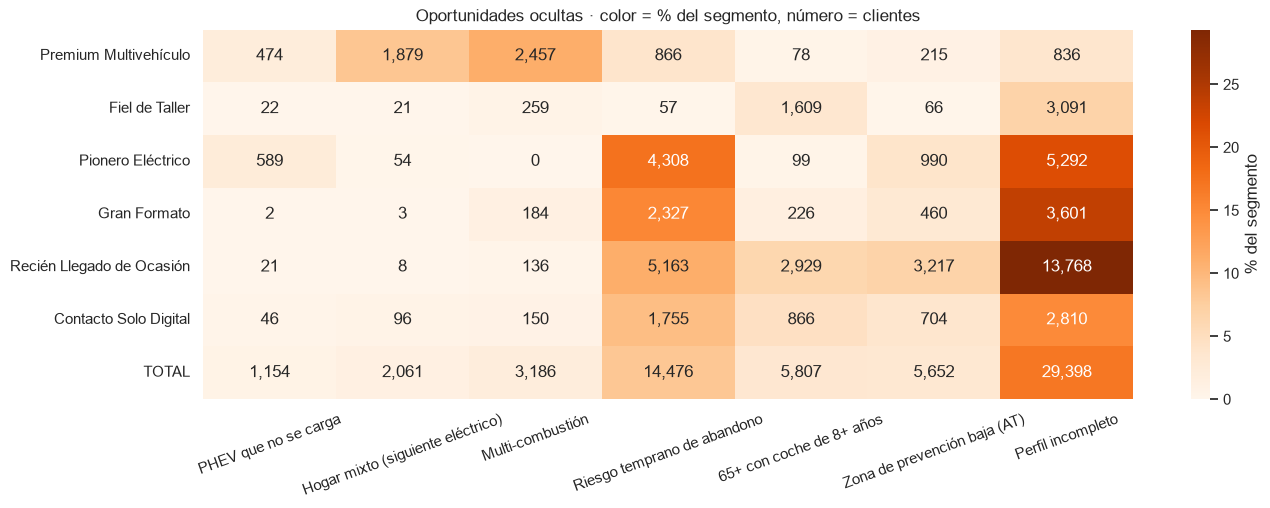

segmento,Premium Multivehículo,Fiel de Taller,Pionero Eléctrico,Gran Formato,Recién Llegado de Ocasión,Contacto Solo Digital
% de sus PHEV que no se cargan,18.9,13.7,12.7,33.3,29.6,9.4


In [26]:
SENALES = {"phev_sin_cargar": "PHEV que no se carga", "hogar_mixto": "Hogar mixto (siguiente eléctrico)",
           "multi_combustion": "Multi-combustión", "riesgo_temprano": "Riesgo temprano de abandono",
           "mayor_coche_viejo": "65+ con coche de 8+ años", "prevencion_baja": "Zona de prevención baja (AT)",
           "perfil_incompleto": "Perfil incompleto"}
ocultas = clientes.groupby("segmento", observed=True)[list(SENALES)].sum().reindex(ORDEN)
ocultas.loc["TOTAL"] = ocultas.sum()
ocultas.columns = list(SENALES.values())
pct_seg = clientes.groupby("segmento", observed=True)[list(SENALES)].mean().reindex(ORDEN).mul(100)
pct_seg.loc["TOTAL"] = clientes[list(SENALES)].mean().mul(100)
pct_seg.columns = list(SENALES.values())
# % de PHEV sin cargar sobre los PHEV con dato (no sobre todos los clientes)
phev_seg = clientes.groupby("segmento", observed=True).apply(lambda g: g["phev_sin_cargar"].sum() / max(g["phev_con_dato"].sum(), 1) * 100).reindex(ORDEN)

fig, ax = plt.subplots(figsize=(15, 4.8))
sns.heatmap(pct_seg, annot=ocultas.map("{:,.0f}".format), fmt="", cmap="Oranges", ax=ax, cbar_kws={"label": "% del segmento"})
ax.set(title="Oportunidades ocultas · color = % del segmento, número = clientes", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=20)
plt.show()
phev_seg.rename("% de sus PHEV que no se cargan").round(1).to_frame().T

### Relectura de los segmentos

- **Premium Multivehículo: el cliente "premium" es el que menos carga su híbrido.** Casi 1 de cada 5 de sus PHEV
  consume como un combustión, más que en Pionero Eléctrico. Encaja con PHEV de **leasing o de empresa** elegidos por
  fiscalidad o imagen. Y es el segmento con más **hogares mixtos** (~1.900) y más **multi-combustión** (~2.500):
  es donde está **el siguiente eléctrico**, como segundo coche o como sustituto del PHEV. La conversación con este
  cliente no es "cambie de coche" sino "**electrifique su garaje**" (wallbox, Mercedes me Charge, eléctrico compacto).
- **Pionero Eléctrico: el más "nuevo", y el de más riesgo temprano.** Coches muy recientes, pero ~4.300 clientes
  (17 %) no han pisado el taller oficial con un coche de ≤ 3 años. Como el eléctrico apenas necesita mantenimiento,
  **la marca pierde el contacto físico** con él. Necesita **otros puntos de contacto**: actualizaciones remotas,
  revisión de batería gratuita, eventos de carga. Además, ~600 de sus PHEV no se cargan: "pionero" a medias.
- **Recién Llegado de Ocasión: concentra lo que no se ve.** Es el segmento con más riesgo temprano en número (~5.200),
  más mayores con coche viejo (~2.900), más de la mitad de los clientes de **zonas de prevención baja** (~3.200) y el perfil
  más incompleto (29 % sin género). Una relación **débil en datos y en contacto**: el objetivo no es venderle un
  coche, es **completar la relación** (datos, primera visita al taller, revisión de seguridad gratuita).
- **Fiel de Taller: el reservorio de los mayores.** ~1.600 clientes de 65+ con coche de 8+ años, que usan poco y
  cuidan en el taller oficial: el público ideal para "**tu coche vale más de lo que crees**" y un cambio a un coche más
  seguro y fácil, no más grande. Riesgo temprano casi nulo.
- **Gran Formato: rural, rápido y con muchos clientes sin taller.** El de mayor velocidad media (carretera) y un 15 %
  de riesgo temprano: probablemente furgonetas atendidas en **talleres independientes cercanos**. Una red de
  **servicio móvil** o talleres asociados en zonas rurales retendría a este cliente.
- **Contacto Solo Digital:** sin señales propias destacables; su reto sigue siendo el canal.

**Idea transversal:** el taller oficial no es solo un negocio de posventa, es **el principal termómetro de la
relación**. Un indicador "coche nuevo sin primera visita" en el CRM permitiría actuar **antes** de que el cliente
desaparezca, en todos los segmentos.

## 9. Salud y ergonomía por segmento

En el Reto 1 (apartado 6.3) se estimó, para cada cliente, la **probabilidad esperada** de tener un problema de salud
que afecta al uso del coche, a partir de las estadísticas oficiales de Eurostat **por país, edad y sexo**:
limitación en las actividades por salud (EU-SILC 2023, Austria y Suiza) y problemas lumbares, cervicales y artrosis
(EHIS 2019, solo Austria). `features.py` añade estas probabilidades a cada cliente, junto con la **posición de
conducción** de sus coches (alta: SUV, monovolumen o furgoneta) y la **duración media de sus trayectos** (telemetría).

No es un dato de salud del cliente: es lo que cabe esperar en personas de su edad, sexo y país. Sirve para estimar
cuántos clientes de cada segmento probablemente tienen cada problema y qué equipamiento tiene sentido destacar.

**Fuentes:** Eurostat `hlth_silc_06` (EU-SILC 2023) y `hlth_ehis_cd1e` (EHIS 2019); detalle en
[`Fuentes_Datos_Externos.md`](Fuentes_Datos_Externos.md).

In [27]:
clientes["sin_coche_alto"] = clientes["pct_posicion_alta"].eq(0)
# % sobre los clientes con telemetría
clientes["trayecto_largo"] = clientes["minutos_trayecto"].ge(30).where(clientes["minutos_trayecto"].notna())
ergo = clientes.groupby("segmento", observed=True).agg(
    lim=("p_limitacion", "mean"), lim_grave=("p_limitacion_grave", "mean"),
    lumbar_AT=("p_lumbar", "mean"), cervical_AT=("p_cervical", "mean"), artrosis_AT=("p_artrosis", "mean"),
    posicion_alta=("pct_posicion_alta", "mean"), min_trayecto=("minutos_trayecto", "median"),
    trayectos_30=("trayecto_largo", "mean")).reindex(ORDEN)
ergo[["lim", "lim_grave", "lumbar_AT", "cervical_AT", "artrosis_AT", "posicion_alta", "trayectos_30"]] *= 100
ergo["limitados sin coche alto (esperados)"] = clientes.groupby("segmento", observed=True).apply(
    lambda g: (g["p_limitacion"] * g["sin_coche_alto"]).sum()).reindex(ORDEN)
ergo["65+ sin coche alto"] = clientes.groupby("segmento", observed=True).apply(
    lambda g: (g["age_range"].eq("65+") & g["sin_coche_alto"]).sum()).reindex(ORDEN)
ergo.columns = ["% limitación por salud", "% limitación grave", "% lumbar (AT)", "% cervical (AT)", "% artrosis (AT)",
                "% coches de posición alta", "minutos por trayecto (mediana)", "% trayectos de 30+ min",
                "limitados sin coche alto (esperados)", "65+ sin coche alto"]
ergo.T.round(1)

segmento,Premium Multivehículo,Fiel de Taller,Pionero Eléctrico,Gran Formato,Recién Llegado de Ocasión,Contacto Solo Digital
% limitación por salud,30.8,32.0,33.9,31.4,29.7,33.5
% limitación grave,6.7,6.7,8.0,7.2,6.3,7.6
% lumbar (AT),27.1,27.8,29.0,27.7,24.7,28.8
% cervical (AT),17.4,18.5,19.7,18.2,16.9,19.2
% artrosis (AT),12.2,14.0,15.6,13.6,12.4,15.7
% coches de posición alta,61.4,49.7,72.5,99.6,37.4,53.4
minutos por trayecto (mediana),18.1,17.1,17.4,19.7,17.9,17.5
% trayectos de 30+ min,7.7,4.5,5.0,19.0,5.8,5.9
limitados sin coche alto (esperados),"1,734.7","6,718.3","2,157.7",8.4,"8,152.5","2,674.2"
65+ sin coche alto,850,3346,1634,2,4733,1844


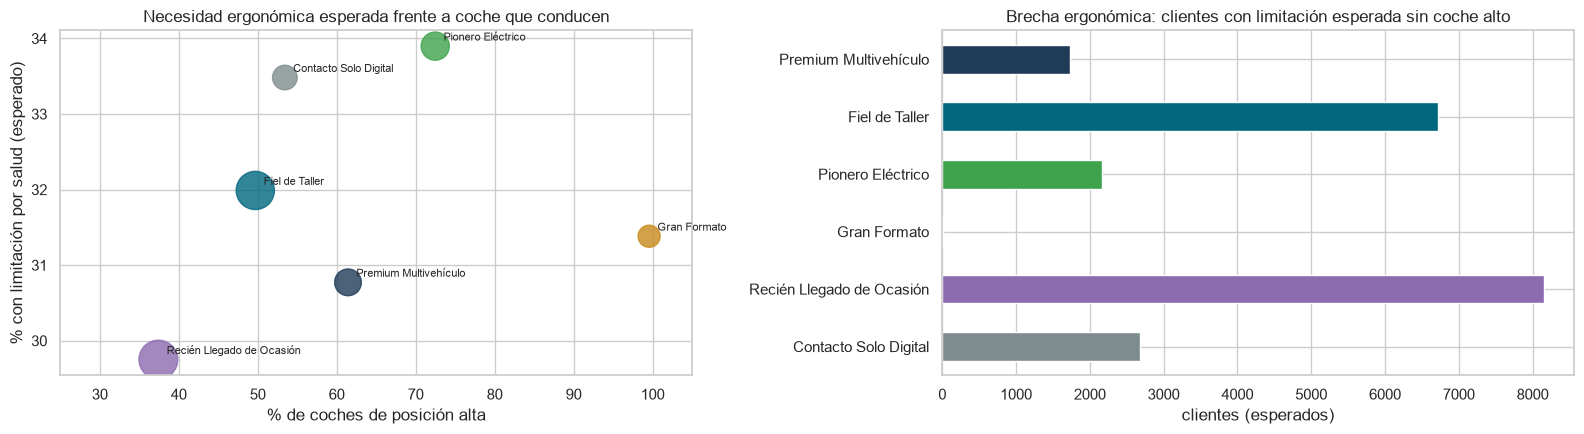

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
x = ergo["% coches de posición alta"]
y = ergo["% limitación por salud"]
axes[0].scatter(x, y, s=clientes["segmento"].value_counts().reindex(ORDEN) / 60, c=[COLORES[s] for s in ORDEN], alpha=.8)
for s in ORDEN:
    axes[0].annotate(s, (x[s], y[s]), fontsize=8, xytext=(6, 4), textcoords="offset points")
axes[0].set(title="Necesidad ergonómica esperada frente a coche que conducen", xlabel="% de coches de posición alta",
            ylabel="% con limitación por salud (esperado)", xlim=(25, 105))
ergo["limitados sin coche alto (esperados)"].plot.barh(ax=axes[1], color=[COLORES[s] for s in ORDEN])
axes[1].invert_yaxis()
axes[1].set(title="Brecha ergonómica: clientes con limitación esperada sin coche alto", xlabel="clientes (esperados)", ylabel="")
plt.tight_layout()
plt.show()

**Lectura por segmento:**
- **Recién Llegado de Ocasión: la mayor brecha ergonómica.** Es el segmento con menos coches altos (~37 %) y, aunque es
  el más joven, por su tamaño concentra la mayor cantidad de clientes con limitación esperada **sin coche alto**
  (~8.200) y de mayores de 65 sin coche alto (~4.700). Su entrada natural es un **seminuevo Mercedes-Benz Certified de
  posición alta** (GLA, GLB, Clase B), con el argumento "entra y sal sin esfuerzo".
- **Fiel de Taller: la segunda brecha** (~6.700 y ~3.300). Su coche está en edad de renovación: es el momento de
  proponerle un **GLB o GLC** con KEYLESS-GO y portón eléctrico, y probarlo en el propio taller que ya visita.
- **Pionero Eléctrico y Contacto Solo Digital: la mayor necesidad esperada** (~34 % con limitación, por tener los
  clientes de más edad), pero Pionero ya conduce sobre todo coches altos (EQA/EQB, GLC). Para ellos la ergonomía está
  en el **interior**: asientos multicontorno, cámara de 360° y Active Parking Assist (cervical).
- **Gran Formato: la ergonomía del trabajo.** Ya va sentado alto (furgonetas), pero hace **los trayectos más largos**
  (~1 de cada 5 de los que tienen telemetría hace trayectos medios de 30+ minutos, frente a un 5-8 % en el resto). Para el dolor lumbar: **asientos de confort con apoyo lumbar** y
  suspensión de calidad en la Clase V y la Sprinter.
- **Premium Multivehículo:** la necesidad esperada más baja, pero trayectos más largos que la media y 1 de cada 4
  clientes sin coche alto (berlinas y coupés). El argumento es el **confort**: masaje, ENERGIZING, AIRMATIC.

**Idea transversal:** la brecha ergonómica suma unos 21.000 clientes con limitación esperada que conducen un coche que
no es alto. Es un argumento de renovación **distinto del precio o la tecnología**: el **bienestar al volante**, que
además encaja con la imagen de marca de Mercedes-Benz. Siempre en clave de comodidad, nunca de salud ni de edad.

## 10. Resumen

| Segmento | % | Rasgo clave | Prioridad comercial |
|---|---|---|---|
| Premium Multivehículo | 12,9 % | Varios coches, leasing, gama alta | Retener y renovar (mayor valor) |
| Fiel de Taller | 26,2 % | Usa mucho el taller oficial, coche de ~5 años | Planes de mantenimiento y renovación |
| Pionero Eléctrico | 14,3 % | 97 % electrificado, coches nuevos | Gama EQ y servicios eléctricos |
| Gran Formato | 8,8 % | Furgonetas (V-Class/Vito, Sprinter), particulares | Renovación de furgoneta, eVans |
| Recién Llegado de Ocasión | 27,1 % | Reciente, coche antiguo, sin taller oficial | Primer coche nuevo, atraer al taller, evitar abandono |
| Contacto Solo Digital | 10,9 % | Solo consiente email | Recaptar consentimientos; solo canal digital |

**Hallazgos de interpretación:**
- Las diferencias de taller son de **comportamiento**, no de la edad del coche (comprobado en coches de la misma edad).
- El poder adquisitivo de la zona y la forma de conducir **no diferencian** segmentos.
- "Recién Llegado de Ocasión" se basa en una **hipótesis** que conviene validar con datos de ventas.
- "Contacto Solo Digital" es un segmento de **canal**: se combina con las ofertas de los demás.
- "Premium Multivehículo" se divide en 3 sub-perfiles estables para afinar campañas.
- **Salud y seguridad vial (datos oficiales externos):** los segmentos viven en zonas parecidas; solo **Gran Formato**
  destaca (18-20 % más lejos del hospital en ambos países y más accidentes graves en Austria) y **Recién Llegado de
  Ocasión** es el más urbano. Meter estos indicadores en el K-Means no aporta (mismos segmentos, peor silhouette): se
  usan como **capa de perfilado** para elegir a quién de cada segmento dirigir un mensaje de seguridad.
- **Oportunidades ocultas (apartado 8):** Premium es el que menos carga sus híbridos y donde está el siguiente
  eléctrico; Pionero Eléctrico pierde el contacto con el taller; Recién Llegado concentra el riesgo y los datos
  incompletos; Fiel de Taller reúne a los mayores con coche antiguo y poco usado. "Coche nuevo sin primera visita al
  taller" es una alerta de abandono válida para todos los segmentos.
- **Salud y ergonomía (apartado 9):** con datos oficiales de Eurostat por edad y sexo, se esperan ~21.000 clientes con
  limitación por salud que conducen un coche que no es alto. La mayor brecha está en Recién Llegado de Ocasión y Fiel
  de Taller; Gran Formato necesita ergonomía de trabajo (trayectos largos). Argumento de renovación: bienestar al volante.